In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
housing = fetch_california_housing(as_frame=True)

# Convert into DataFrame
df = housing.frame

# Display first 5 rows
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
# Display number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (20640, 9)

Column Names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1

In [4]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with median
df = df.fillna(df.median(numeric_only=True))

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("Data preprocessing completed!")

Missing values before cleaning:
0
Missing values after cleaning:
0
Data preprocessing completed!


In [5]:
# Input feature
X = df[['MedInc']]

# Target variable
y = df['MedHouseVal']

print("Input data:")
print(X.head())

print("\nOutput data:")
print(y.head())

Input data:
   MedInc
0  8.3252
1  8.3014
2  7.2574
3  5.6431
4  3.8462

Output data:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 1)
Testing data: (4128, 1)


In [7]:
# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Simple Linear Regression model trained successfully!")

Simple Linear Regression model trained successfully!


In [8]:
# Predict house prices
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred[:10]
})

print(results)

   Actual Price  Predicted Price
0       0.47700         1.149589
1       0.45800         1.506069
2       5.00001         1.903937
3       2.18600         2.850594
4       2.78000         2.006633
5       1.58700         2.421652
6       1.98200         2.576472
7       1.57500         1.992292
8       3.40000         2.458932
9       4.46600         3.846774


In [9]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

Model Evaluation
----------------------
MAE: 0.629908653009376
MSE: 0.7091157771765549
R2 Score: 0.45885918903846656


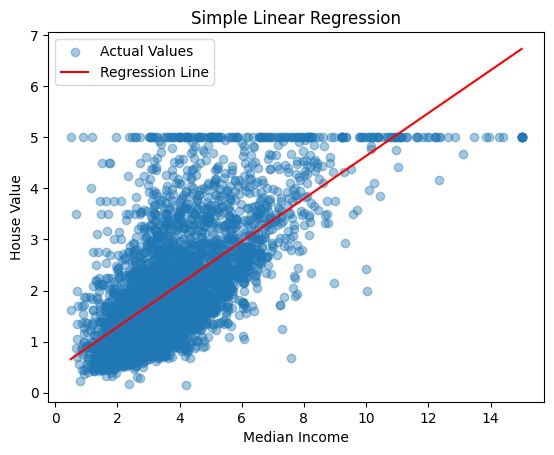

In [10]:
# Sort values for plotting
sorted_data = X_test.copy()
sorted_data['Actual'] = y_test
sorted_data['Predicted'] = y_pred
sorted_data = sorted_data.sort_values('MedInc')

# Plot actual values
plt.scatter(
    sorted_data['MedInc'],
    sorted_data['Actual'],
    label='Actual Values',
    alpha=0.4
)

# Plot regression line
plt.plot(
    sorted_data['MedInc'],
    sorted_data['Predicted'],
    color='red',
    label='Regression Line'
)

plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [11]:
print("Intercept:", model.intercept_)

print("Coefficient:", model.coef_[0])

Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271


In [12]:
# Select multiple input features
X_multi = df.drop('MedHouseVal', axis=1)

# Target variable
y_multi = df['MedHouseVal']

# Split the data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42
)

print("Multiple regression data prepared!")

Multiple regression data prepared!


In [13]:
# Create model
multi_model = LinearRegression()

# Train model
multi_model.fit(X_train_multi, y_train_multi)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [14]:
# Make predictions
y_multi_pred = multi_model.predict(X_test_multi)

# Display actual and predicted values
multi_results = pd.DataFrame({
    'Actual Price': y_test_multi.values[:10],
    'Predicted Price': y_multi_pred[:10]
})

print(multi_results)

   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615


In [15]:
# Calculate metrics
mae_multi = mean_absolute_error(
    y_test_multi, y_multi_pred
)

mse_multi = mean_squared_error(
    y_test_multi, y_multi_pred
)

r2_multi = r2_score(
    y_test_multi, y_multi_pred
)

print("Multiple Linear Regression Evaluation")
print("-------------------------------------")
print("MAE:", mae_multi)
print("MSE:", mse_multi)
print("R2 Score:", r2_multi)

Multiple Linear Regression Evaluation
-------------------------------------
MAE: 0.5332001304956561
MSE: 0.5558915986952438
R2 Score: 0.5757877060324512


In [16]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'R2 Score'],
    'Simple Regression': [mae, mse, r2],
    'Multiple Regression': [
        mae_multi,
        mse_multi,
        r2_multi
    ]
})

print(comparison)

     Metric  Simple Regression  Multiple Regression
0       MAE           0.629909             0.533200
1       MSE           0.709116             0.555892
2  R2 Score           0.458859             0.575788


In [17]:
coefficients = pd.DataFrame({
    'Feature': X_multi.columns,
    'Coefficient': multi_model.coef_
})

print(coefficients)

      Feature  Coefficient
0      MedInc     0.448675
1    HouseAge     0.009724
2    AveRooms    -0.123323
3   AveBedrms     0.783145
4  Population    -0.000002
5    AveOccup    -0.003526
6    Latitude    -0.419792
7   Longitude    -0.433708


              MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc      1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge   -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms    0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms  -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population  0.004834 -0.296244 -0.072213  -0.066197    1.000000  0.069863   
AveOccup    0.018766  0.013191 -0.004852  -0.006181    0.069863  1.000000   
Latitude   -0.079809  0.011173  0.106389   0.069721   -0.108785  0.002366   
Longitude  -0.015176 -0.108197 -0.027540   0.013344    0.099773  0.002476   

            Latitude  Longitude  
MedInc     -0.079809  -0.015176  
HouseAge    0.011173  -0.108197  
AveRooms    0.106389  -0.027540  
AveBedrms   0.069721   0.013344  
Population -0.108785   0.099773  
AveOccup    0.002366   0.002476  
Latitude    1.000000  -0.924664  
Longitude  -0.924664   1.000000  


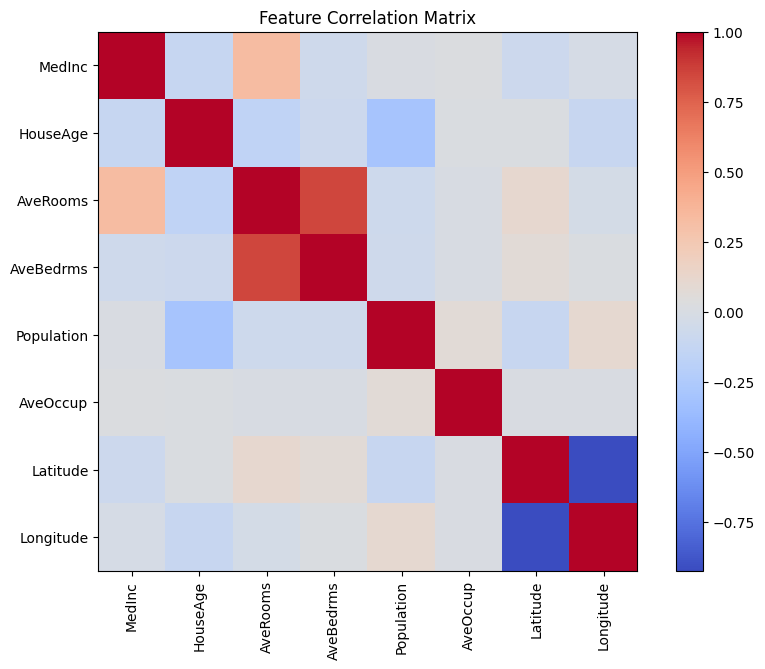

In [18]:
correlation = X_multi.corr()

print(correlation)

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap='coolwarm')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")

plt.show()

In [19]:
df.to_csv(
    'California_Housing_Cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [20]:
from google.colab import files

files.download('California_Housing_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>